# 01 - Data Cleaning & EDA
## Inventory Demand Forecasting (M5 subset) - AML Project, Phase 1

**What this notebook does**
1. Loads the raw M5 files and checks their quality (is the data really "dirty"?).
2. Cleans the data and picks the project subset (1 store, 1 category, 40 SKUs).
3. Creates the **potential_unavailable** flag (a proxy, *not* a real stockout label).
4. Saves the cleaned file `data/processed/m5_clean_panel.csv`.
5. Does the EDA (exploratory data analysis) that justifies our feature and model choices.

The next notebook (`02_model_comparison.ipynb`) only uses the cleaned file from here.

In [1]:
import sys
sys.path.insert(0, "../src")          # so we can import our own modules from src/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import data

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
FIG = "../outputs/figures/"           # all figures are saved here

## 1. Load the raw data
M5 has three files: **sales** (units sold per item per day), **calendar** (dates, events, SNAP days) and **prices** (weekly selling price).

In [2]:
calendar, sales, prices = data.load_raw("../data/raw")
print("calendar:", calendar.shape)
print("sales   :", sales.shape, "-> 30,490 series x (6 id columns + 1,941 days)")
print("prices  :", prices.shape)
sales.iloc[:3, :10]

calendar: (1969, 14)
sales   : (30490, 1947) -> 30,490 series x (6 id columns + 1,941 days)
prices  : (6841121, 4)


,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2,d_3,d_4
0,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0
1,HOBBIES_1_002_CA_1_evaluation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0
2,HOBBIES_1_003_CA_1_evaluation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0


## 2. Raw data quality audit
Before cleaning, we measure what is wrong. Each check below is on the **full raw files**.

In [3]:
# --- 2.1 missing values in each file
print("Missing values - calendar:")
print(calendar.isna().sum()[calendar.isna().sum() > 0], "\n")
print("Missing values - sales :", int(sales.isna().sum().sum()))
print("Missing values - prices:", int(prices.isna().sum().sum()))

Missing values - calendar:
event_name_1    1807
event_type_1    1807
event_name_2    1964
event_type_2    1964
dtype: int64 

Missing values - sales : 0
Missing values - prices: 0


In [4]:
# --- 2.2 duplicates, negative values, date coverage
day_cols = [c for c in sales.columns if c.startswith("d_")]
print("duplicate series ids        :", sales["id"].duplicated().sum())
print("duplicate calendar dates    :", calendar["date"].duplicated().sum())
print("duplicate price rows        :", prices.duplicated(["store_id", "item_id", "wm_yr_wk"]).sum())
print("negative sales values       :", int((sales[day_cols].values < 0).sum()))
print("days in sales / in calendar :", len(day_cols), "/", len(calendar))
print("sales dates                 :", calendar["date"].iloc[0], "to", calendar["date"].iloc[len(day_cols) - 1])

duplicate series ids        : 0
duplicate calendar dates    : 0


duplicate price rows        : 0
negative sales values       : 0
days in sales / in calendar : 1941 / 1969
sales dates                 : 2011-01-29 to 2016-05-22


In [5]:
# --- 2.3 how many zeros? (very important for forecasting)
values = sales[day_cols].values
print(f"share of zero-sales cells in all of M5: {(values == 0).mean():.1%}")

# --- 2.4 SKUs that start selling late (zeros before the product existed)
first_sale = (values > 0).argmax(axis=1) + 1
print(f"series whose first sale is after day 200: {(first_sale > 200).mean():.1%}")
print(f"series that never sold anything          : {(values.sum(axis=1) == 0).sum()}")

share of zero-sales cells in all of M5: 68.0%


series whose first sale is after day 200: 48.5%
series that never sold anything          : 0


In [6]:
# --- 2.5 price coverage: how many (item, store, week) combos have a price?
n_weeks = calendar["wm_yr_wk"].nunique()
expected = sales[["item_id", "store_id"]].drop_duplicates().shape[0] * n_weeks
print(f"price rows present: {len(prices):,} of {expected:,} possible -> {len(prices) / expected:.1%}")
print("A missing price in a week means the item was NOT on sale in that store that week.")

price rows present: 6,841,121 of 8,598,180 possible -> 79.6%
A missing price in a week means the item was NOT on sale in that store that week.


**Issues found in the raw data (what the cleaning step must handle)**

| Issue | Where | How we handle it |
|---|---|---|
| Sales are in *wide* format (1,941 day columns) | sales | melt to long format (one row per SKU per day) |
| Days are called `d_1, d_2, ...` not dates | sales | join with calendar to get real dates |
| Event columns are mostly empty (NaN) | calendar | NaN means "no event" -> fill with `"None"` |
| Prices missing for many item-weeks | prices | do **not** invent prices; create `price_missing` flag |
| A huge number of zeros (many are before launch or while unavailable) | sales | keep zeros, add `potential_unavailable` proxy flag |
| Items that start selling very late | sales | select only SKUs with long history |
| Series with almost no sales | sales | drop SKUs with mean daily sales < 0.3 |
| Very large size (30,490 series, 6.8M price rows) | all | work with one store + one category + 40 SKUs |

## 3. Choose the project subset (PRD section 5.1)
One store (**CA_1**), one category (**FOODS**), **40 SKUs**. FOODS items are SNAP-eligible, so the SNAP calendar feature is meaningful.

We do not pick 40 random items. The function `select_skus` keeps SKUs that started selling early and are not almost-empty, then takes evenly spaced ones sorted by average sales. So the subset has fast sellers *and* slow ones.

In [7]:
store_food = sales[(sales["store_id"] == data.STORE) & (sales["cat_id"] == data.CATEGORY)]
print("CA_1 FOODS series available:", len(store_food))

chosen = data.select_skus(sales)
print("SKUs chosen:", len(chosen))
print(chosen["dept_id"].value_counts().to_dict())
chosen[["item_id", "dept_id"]].head(8)

CA_1 FOODS series available: 1437
SKUs chosen: 40
{'FOODS_3': 23, 'FOODS_2': 11, 'FOODS_1': 6}


,item_id,dept_id
0,FOODS_1_034,FOODS_1
20,FOODS_3_528,FOODS_3
41,FOODS_2_163,FOODS_2
61,FOODS_3_506,FOODS_3
81,FOODS_2_263,FOODS_2
102,FOODS_3_081,FOODS_3
122,FOODS_3_395,FOODS_3
142,FOODS_1_209,FOODS_1


## 4. Build the clean panel
`build_panel` (in `src/data.py`) does: wide -> long, add dates/calendar, fill event NaNs, join prices, create flags.

In [8]:
panel = data.build_panel(chosen, calendar, prices)
print(panel.shape, "= 40 SKUs x 1,941 days")
panel[["item_id", "date", "sales", "weekday", "event_name_1", "snap", "sell_price", "price_missing", "potential_unavailable"]].head()

(77640, 24) = 40 SKUs x 1,941 days


,item_id,date,sales,weekday,event_name_1,snap,sell_price,price_missing,potential_unavailable
0,FOODS_1_034,2011-01-29,0,Saturday,None,0,NaN,1,1
1,FOODS_1_034,2011-01-30,0,Sunday,None,0,NaN,1,1
2,FOODS_1_034,2011-01-31,0,Monday,None,0,NaN,1,1
3,FOODS_1_034,2011-02-01,0,Tuesday,None,1,NaN,1,1
4,FOODS_1_034,2011-02-02,0,Wednesday,None,1,NaN,1,1


In [9]:
# quality checks on the cleaned panel (these raise an error if something is wrong)
counts = data.check_panel(panel)
print("no duplicates, no negative sales, every SKU has all", counts["count"].iloc[0], "days")
print("dates:", panel["date"].min().date(), "to", panel["date"].max().date())
print("remaining missing values per column:")
print(panel.isna().sum()[panel.isna().sum() > 0])

no duplicates, no negative sales, every SKU has all 1941 days
dates: 2011-01-29 to 2016-05-22
remaining missing values per column:
sell_price           679
sell_price_filled    679
dtype: int64


## 5. Availability proxy (PRD section 5.2)
M5 has **no stockout column**. A zero can mean (a) nobody wanted the item, or (b) the item could not be bought.

Our conservative proxy: a day is `potential_unavailable = 1` when **sales are 0 AND the item has no price that week** (no price = not on sale).

> This is a *proxy*, not "stockout truth". We never replace those zeros with estimated demand. We only use the flag to check how much it matters for accuracy.

In [10]:
zero_days = panel[panel["sales"] == 0]
print(f"zero-sales days            : {len(zero_days):,} ({len(zero_days) / len(panel):.1%} of all days)")
print(f"  ... with a price (real zero demand) : {(zero_days['price_missing'] == 0).sum():,}")
print(f"  ... without price (potential unavailable): {zero_days['potential_unavailable'].sum():,}")

flag_by_sku = panel.groupby("item_id")["potential_unavailable"].sum().sort_values(ascending=False)
print("\nSKUs with most potential_unavailable days:")
print(flag_by_sku.head(5))
print("SKUs with none:", (flag_by_sku == 0).sum(), "of", len(flag_by_sku))

zero-sales days            : 33,327 (42.9% of all days)
  ... with a price (real zero demand) : 32,648
  ... without price (potential unavailable): 679

SKUs with most potential_unavailable days:
item_id
FOODS_2_109    189
FOODS_3_308    182
FOODS_3_365    175
FOODS_1_034     70
FOODS_3_376     21
Name: potential_unavailable, dtype: int64
SKUs with none: 31 of 40


In [11]:
# are the flagged days BEFORE the SKU's first sale (not launched yet) or AFTER it (a real gap)?
panel = panel.sort_values(["item_id", "date"])
sold_before = panel.groupby("item_id")["sales"].cumsum() > 0       # has the SKU sold anything yet?
flagged = panel["potential_unavailable"] == 1
print("flagged days before the first sale (pre-launch):", int((flagged & ~sold_before).sum()))
print("flagged days after  the first sale (mid-history):", int((flagged & sold_before).sum()))

flagged days before the first sale (pre-launch): 679
flagged days after  the first sale (mid-history): 0


**Honest finding:** in CA_1 FOODS *all* flagged days are pre-launch days (the item had no price because it was not on sale yet). We also checked the whole CA_1 FOODS category (1,437 items): no item has a mid-history week without a price that also has zero sales. So in our subset the proxy never touches the forecast windows. We keep the flag (the PRD requires it) and report this limitation instead of claiming we found stockouts.

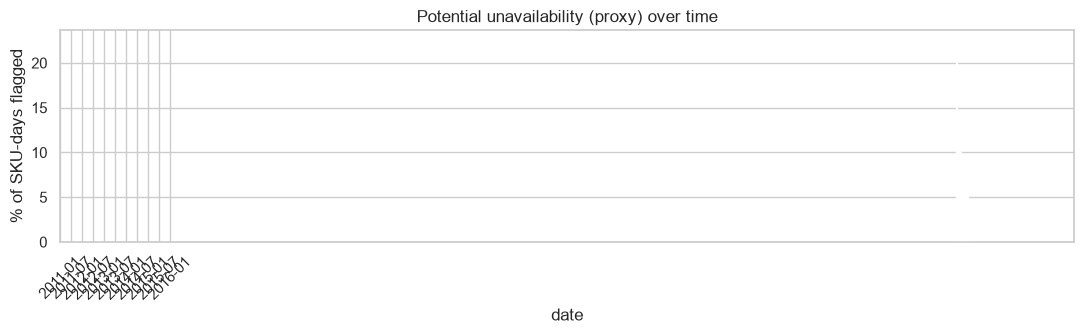

In [12]:
# when do the flagged days happen? (share of SKUs flagged per month)
monthly = panel.groupby(panel["date"].dt.to_period("M"))["potential_unavailable"].mean() * 100
plt.figure(figsize=(11, 3.5))
monthly.plot(kind="bar", color="tab:red")
plt.xticks(range(0, len(monthly), 6), [str(m) for m in monthly.index[::6]], rotation=45)
plt.ylabel("% of SKU-days flagged")
plt.title("Potential unavailability (proxy) over time")
plt.tight_layout(); plt.savefig(FIG + "01_unavailability_over_time.png", dpi=120); plt.show()

## 6. Outliers
We mark very high sales days (more than 5 standard deviations above that SKU's mean) in a column `high_sales_flag`, but we **do not remove or cap them**. In retail, spikes are usually real (events, holidays, promotions), and deleting them would make the forecasts look better than they really are.

In [13]:
mean_sku = panel.groupby("item_id")["sales"].transform("mean")
std_sku = panel.groupby("item_id")["sales"].transform("std")
panel["high_sales_flag"] = (panel["sales"] > mean_sku + 5 * std_sku).astype(int)
print("high sales days flagged:", panel["high_sales_flag"].sum(), f"({panel['high_sales_flag'].mean():.2%})")
panel.loc[panel["high_sales_flag"] == 1, ["item_id", "date", "sales", "event_name_1"]].sort_values("sales", ascending=False).head(8)

high sales days flagged: 165 (0.21%)


,item_id,date,sales,event_name_1
35884,FOODS_3_090,2013-09-01,599,None
35883,FOODS_3_090,2013-08-31,432,None
35905,FOODS_3_090,2013-09-22,369,None
54775,FOODS_3_412,2012-03-31,98,None
55298,FOODS_3_412,2013-09-05,96,None
73578,FOODS_3_723,2015-11-25,95,None
72763,FOODS_3_723,2013-09-01,90,None
72776,FOODS_3_723,2013-09-14,89,None


## 7. Save the cleaned dataset

In [14]:
keep = ["item_id", "dept_id", "cat_id", "store_id", "state_id", "date", "d", "wm_yr_wk", "weekday", "wday",
        "month", "year", "event_name_1", "event_type_1", "event_name_2", "event_type_2", "is_event", "snap",
        "sales", "sell_price", "sell_price_filled", "price_missing", "potential_unavailable", "high_sales_flag"]
clean = panel[keep]
clean.to_csv("../data/processed/m5_clean_panel.csv", index=False)

check = data.load_clean_panel("../data/processed/m5_clean_panel.csv")
print("saved and re-loaded:", check.shape, "| identical sales:", (check["sales"].values == clean["sales"].values).all())

saved and re-loaded: (77640, 24) | identical sales: True


---
# EDA
We work on the cleaned panel. Every plot ends in a short "what we learn" note, because the findings decide the features/models in notebook 02.

### 8. The target: daily unit sales

count    77640.00
mean         3.90
std         14.25
min          0.00
25%          0.00
50%          1.00
75%          3.00
max        599.00
Name: sales, dtype: float64
zero share: 42.9%


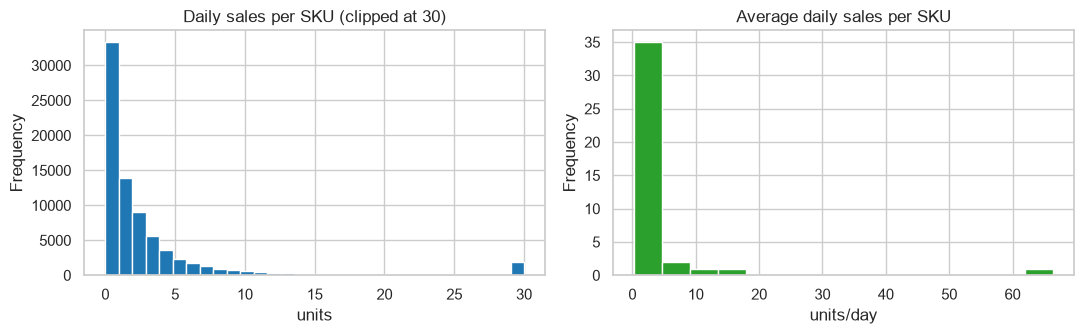

In [15]:
print(panel["sales"].describe().round(2))
print(f"zero share: {(panel['sales'] == 0).mean():.1%}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
panel["sales"].clip(upper=30).plot(kind="hist", bins=31, ax=ax[0], color="tab:blue")
ax[0].set_title("Daily sales per SKU (clipped at 30)"); ax[0].set_xlabel("units")
panel.groupby("item_id")["sales"].mean().plot(kind="hist", bins=15, ax=ax[1], color="tab:green")
ax[1].set_title("Average daily sales per SKU"); ax[1].set_xlabel("units/day")
plt.tight_layout(); plt.savefig(FIG + "02_sales_distribution.png", dpi=120); plt.show()

**What we learn:** sales are small non-negative **counts** with many zeros and a long right tail. So a normal-distribution assumption is only an approximation, and predictions should never be negative.

### 9. Trend over time

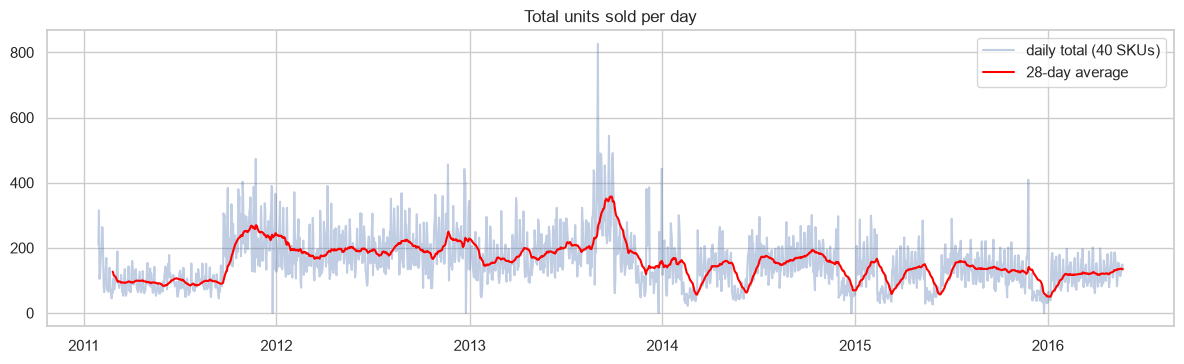

In [16]:
total = panel.groupby("date")["sales"].sum()
plt.figure(figsize=(12, 3.8))
plt.plot(total.index, total.values, alpha=0.35, label="daily total (40 SKUs)")
plt.plot(total.index, total.rolling(28).mean(), color="red", label="28-day average")
plt.title("Total units sold per day"); plt.legend()
plt.tight_layout(); plt.savefig(FIG + "03_total_sales_trend.png", dpi=120); plt.show()

**What we learn:** the level is not constant. There is a jump in late 2011 (more SKUs start selling), a spike in Aug-Sep 2013 (caused by one SKU, FOODS_3_090, see the outlier table), slow ups and downs after that, and near-zero days around Christmas (store closed). Because the level keeps changing, a filter that tracks a moving level (Kalman) is a sensible model to test.

### 10. Weekly and yearly seasonality

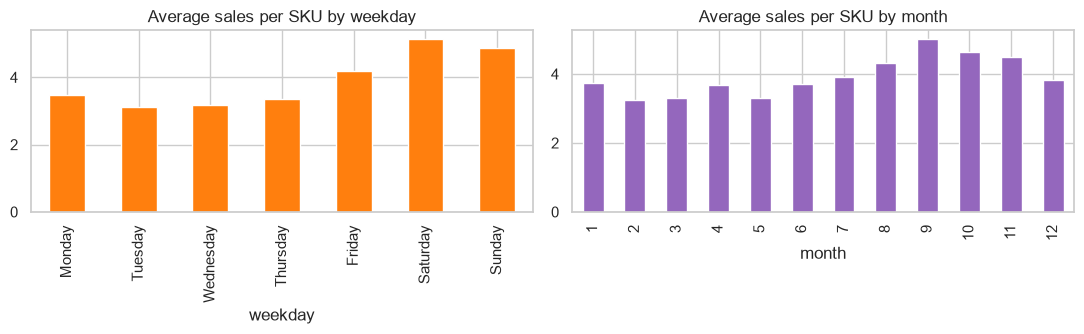

weekend vs Monday-Thursday uplift: 53%


In [17]:
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
by_weekday = panel.groupby("weekday")["sales"].mean().reindex(order)
by_month = panel.groupby("month")["sales"].mean()

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
by_weekday.plot(kind="bar", ax=ax[0], color="tab:orange"); ax[0].set_title("Average sales per SKU by weekday")
by_month.plot(kind="bar", ax=ax[1], color="tab:purple"); ax[1].set_title("Average sales per SKU by month")
plt.tight_layout(); plt.savefig(FIG + "04_weekday_month.png", dpi=120); plt.show()
print(f"weekend vs Monday-Thursday uplift: {by_weekday[['Saturday','Sunday']].mean() / by_weekday[['Monday','Tuesday','Wednesday','Thursday']].mean() - 1:.0%}")

**What we learn:** a strong **weekly cycle** (weekends sell much more). The yearly (month) pattern is weaker. So we use lag-7, lag-14, lag-28 and day-of-week as features, and lag-7 seasonal naive is a serious baseline.

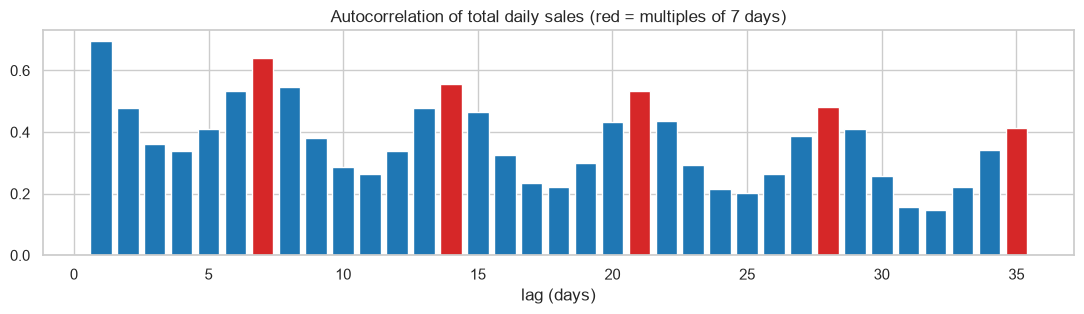

In [18]:
# autocorrelation of total daily sales: how similar is a day to the day k days earlier?
lags = range(1, 36)
acf = [total.autocorr(lag=k) for k in lags]
plt.figure(figsize=(11, 3.3))
plt.bar(lags, acf, color=["tab:red" if k % 7 == 0 else "tab:blue" for k in lags])
plt.title("Autocorrelation of total daily sales (red = multiples of 7 days)")
plt.xlabel("lag (days)")
plt.tight_layout(); plt.savefig(FIG + "05_autocorrelation.png", dpi=120); plt.show()

**What we learn:** the peaks at lags 7, 14, 21, 28 confirm the weekly pattern. This is the reason for the PRD's lag choices (1, 7, 14, 28).

### 11. Events and SNAP days

average sales  no event / event : {0: 3.909, 1: 3.841}
average sales  no SNAP  / SNAP  : {0: 3.779, 1: 4.155}


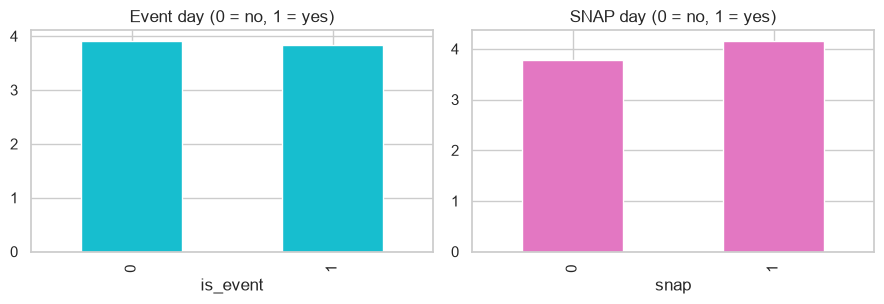

In [19]:
event_effect = panel.groupby("is_event")["sales"].mean()
snap_effect = panel.groupby("snap")["sales"].mean()
print("average sales  no event / event :", event_effect.round(3).to_dict())
print("average sales  no SNAP  / SNAP  :", snap_effect.round(3).to_dict())

fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
event_effect.plot(kind="bar", ax=ax[0], color="tab:cyan"); ax[0].set_title("Event day (0 = no, 1 = yes)")
snap_effect.plot(kind="bar", ax=ax[1], color="tab:pink"); ax[1].set_title("SNAP day (0 = no, 1 = yes)")
plt.tight_layout(); plt.savefig(FIG + "06_event_snap.png", dpi=120); plt.show()

**What we learn:** SNAP days sell about 10% more on average. Event days show no clear average uplift (about the same as normal days) - the events are different kinds (sports, religious, national) and some raise sales while others lower them. Both are known in advance and cost nothing to add, so we keep them as features and let the model decide.

### 12. Price and sales

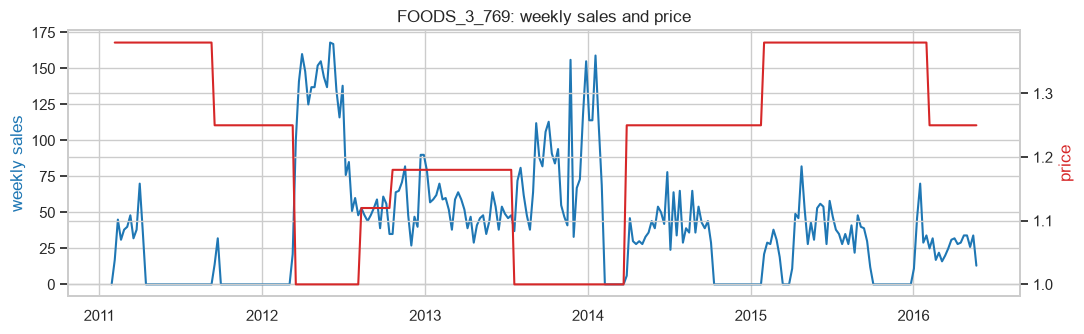

median correlation between price and weekly sales over SKUs: -0.15


In [20]:
# one example SKU: weekly price and weekly sales
example = panel[panel["item_id"] == panel.groupby("item_id")["sales"].mean().sort_values().index[-5]]
weekly = example.groupby("wm_yr_wk").agg(date=("date", "first"), sales=("sales", "sum"), price=("sell_price", "mean"))
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(weekly["date"], weekly["sales"], color="tab:blue"); ax.set_ylabel("weekly sales", color="tab:blue")
ax2 = ax.twinx(); ax2.plot(weekly["date"], weekly["price"], color="tab:red"); ax2.set_ylabel("price", color="tab:red")
ax.set_title(f"{example['item_id'].iloc[0]}: weekly sales and price")
plt.tight_layout(); plt.savefig(FIG + "07_price_vs_sales.png", dpi=120); plt.show()

# correlation of weekly price change and weekly sales change over all SKUs
cors = []
for item, g in panel.groupby("item_id"):
    w = g.groupby("wm_yr_wk").agg(sales=("sales", "sum"), price=("sell_price", "mean")).dropna()
    if w["price"].std() > 0:
        cors.append(w["sales"].corr(w["price"]))
print(f"median correlation between price and weekly sales over SKUs: {np.median(cors):.2f}")

**What we learn:** the price moves only a little for most food items and its relationship to sales is weak (median correlation about -0.15, i.e. slightly lower sales at higher prices). We use price only to build the availability proxy (and keep it out of the models to stay simple and leakage-safe: future prices are not part of the PRD feature list).

### 13. Different SKUs behave differently (demand types)

Syntetos & Boylan classify demand with two numbers:
* **ADI** (average demand interval) = average number of days between sales,
* **CV²** = (std / mean)² of the non-zero sales sizes.

Classes: *smooth* (regular), *erratic* (regular but jumpy sizes), *intermittent* (many zero days), *lumpy* (both).

{'intermittent': 21, 'lumpy': 9, 'smooth': 9, 'erratic': 1}


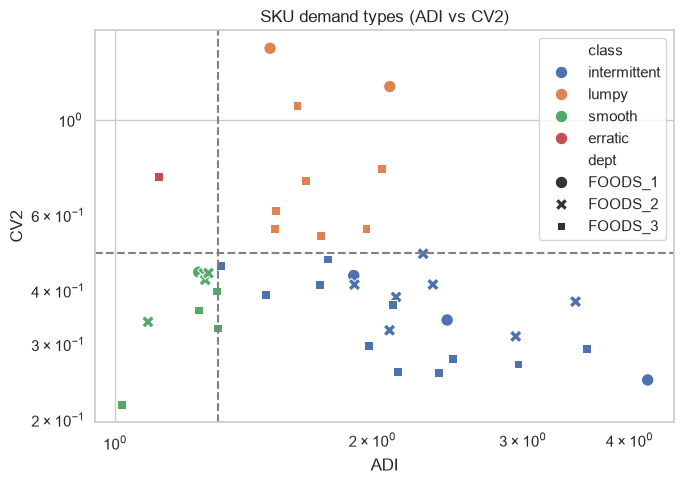

,dept,mean_sales,zero_share,ADI,CV2,class,weekly_strength
item_id,,,,,,,
FOODS_1_034,FOODS_1,0.31,0.77,4.20,0.25,intermittent,0.00
FOODS_3_528,FOODS_3,0.39,0.72,3.57,0.29,intermittent,0.04
FOODS_2_163,FOODS_2,0.46,0.71,3.46,0.38,intermittent,0.02
FOODS_3_506,FOODS_3,0.50,0.66,2.96,0.27,intermittent,0.02
FOODS_2_263,FOODS_2,0.55,0.66,2.94,0.31,intermittent,0.02
FOODS_3_081,FOODS_3,0.60,0.60,2.48,0.28,intermittent,0.05
FOODS_3_395,FOODS_3,0.64,0.58,2.39,0.26,intermittent,0.01
FOODS_1_209,FOODS_1,0.67,0.59,2.45,0.34,intermittent,0.03


In [21]:
rows = []
for item, g in panel.groupby("item_id"):
    s = g.sort_values("date").set_index("date")["sales"]
    cls, adi, cv2 = data.demand_class(s.values)
    rows.append({"item_id": item, "dept": g["dept_id"].iloc[0], "mean_sales": s.mean(), "zero_share": (s == 0).mean(),
                 "ADI": adi, "CV2": cv2, "class": cls, "weekly_strength": data.weekly_strength(s)})
sku_info = pd.DataFrame(rows).set_index("item_id")
sku_info.to_csv("../outputs/sku_classes.csv")
print(sku_info["class"].value_counts().to_dict())

fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=sku_info, x="ADI", y="CV2", hue="class", style="dept", s=80, ax=ax)
ax.axvline(1.32, color="gray", ls="--"); ax.axhline(0.49, color="gray", ls="--")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_title("SKU demand types (ADI vs CV2)")
plt.tight_layout(); plt.savefig(FIG + "08_demand_types.png", dpi=120); plt.show()
sku_info.sort_values("mean_sales").round(2).head(8)

**What we learn:** most of our SKUs are intermittent or lumpy (many zero days), with a smaller group of smooth sellers. This is realistic for retail, and it matches the PRD: a good model for one SKU can fail for another, so we report results *per type of SKU* and not only one average. Note: because most SKUs sell few units, the pooled error is dominated by the few fast sellers.

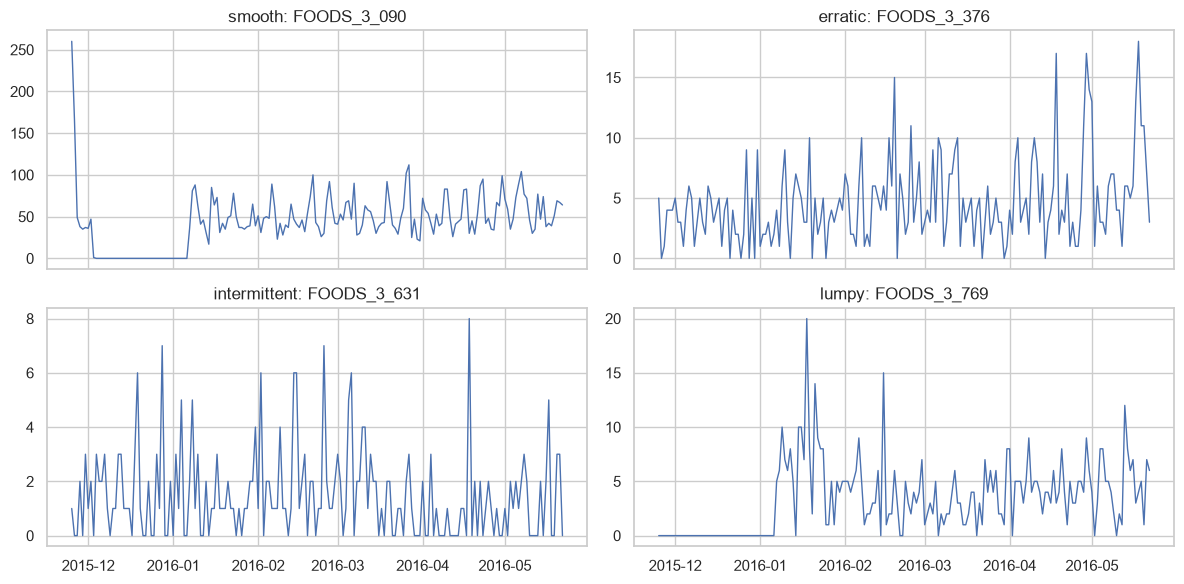

In [22]:
# example series of each demand type
fig, axes = plt.subplots(2, 2, figsize=(12, 6), sharex=True)
for ax, cls in zip(axes.ravel(), ["smooth", "erratic", "intermittent", "lumpy"]):
    candidates = sku_info[sku_info["class"] == cls]
    if len(candidates) == 0:
        ax.set_title(f"{cls}: no SKU in this subset"); continue
    item = candidates["mean_sales"].idxmax()
    s = panel[panel["item_id"] == item].set_index("date")["sales"].tail(180)
    ax.plot(s.index, s.values, lw=1); ax.set_title(f"{cls}: {item}")
plt.tight_layout(); plt.savefig(FIG + "09_example_series.png", dpi=120); plt.show()

### 14. Correlation of the numeric variables

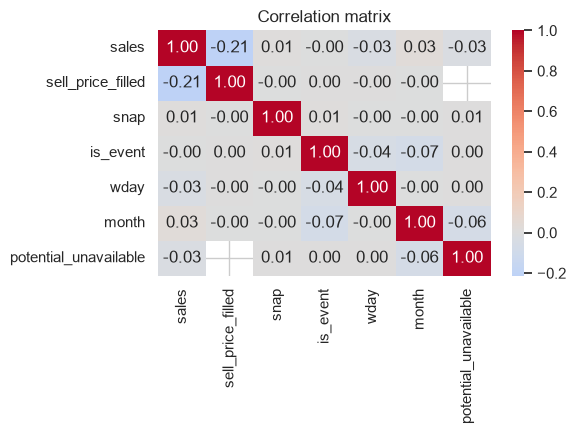

In [23]:
num = panel[["sales", "sell_price_filled", "snap", "is_event", "wday", "month", "potential_unavailable"]]
plt.figure(figsize=(6, 4.5))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.tight_layout(); plt.savefig(FIG + "10_correlation.png", dpi=120); plt.show()

**What we learn:** no single variable explains sales linearly - the strongest signal is in the *past values of sales itself* (lags), which is why we use lag features and sequence models.

---
## 15. EDA summary -> design decisions

| Finding | Decision in notebook 02 |
|---|---|
| Strong weekly cycle, ACF peaks at 7/14/28 | lag features 1, 7, 14, 28; rolling means 7, 28; seasonal naive lag-7 baseline |
| Slowly changing level + noise | Kalman filter with level and trend states |
| Weekends and SNAP days matter; events show no clear average effect | calendar features (all known in advance), model decides |
| Many zeros, count data | clip forecasts at 0, report MAE/WAPE and pinball loss; no replacement of zeros |
| SKUs differ a lot (ADI/CV2) | one global model can share patterns; metrics also reported by SKU type |
| Zeros may mean "not available" (but here the flag only marks pre-launch days) | `potential_unavailable` proxy flag, used only as a diagnostic, limitation reported |